In [2]:
!pip -q install torch-geometric

import os
import csv
import copy
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch_geometric.data import Data
from torch_geometric.nn import GCNConv, GATConv, SAGEConv

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from tqdm.auto import trange
from google.colab import drive

drive.mount('/content/drive')

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Device:", device)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Device: cuda


In [4]:
BASE_DIR = "/content/drive/MyDrive/Insider_Threat_Project"

FEATURE_PATH = os.path.join(
    BASE_DIR,
    "lstm_feature_extraction_result",
    "1-data-test-manual+lstm_seq74.csv"
)

EDGE_PATH = os.path.join(
    BASE_DIR,
    "sample_data/1-data-test-undirected_edge.csv"
)

RESULT_DIR = os.path.join(
    BASE_DIR,
    "ResHybnet_results"
)

MODEL_DIR = os.path.join(
    RESULT_DIR,
    "early_stop_model"
)

os.makedirs(RESULT_DIR, exist_ok=True)
os.makedirs(MODEL_DIR, exist_ok=True)

df_data = pd.read_csv(FEATURE_PATH)
df_e = pd.read_csv(EDGE_PATH)

print("Feature data shape:", df_data.shape)
print("Edge data shape:", df_e.shape)

cols = df_data.columns[5:]

x = torch.tensor(
    df_data[cols].to_numpy(dtype=np.float32),
    dtype=torch.float32
)

y = torch.tensor(
    df_data["label"].to_numpy(dtype=np.int64),
    dtype=torch.long
)

edge_index = torch.tensor(
    df_e[["start", "end"]].to_numpy(dtype=np.int64).T,
    dtype=torch.long
)

assert x.shape == (1908, 10), f"Unexpected feature shape: {x.shape}"
assert y.shape == (1908,), f"Unexpected label shape: {y.shape}"
assert edge_index.shape[0] == 2
assert edge_index.min() >= 0
assert edge_index.max() < len(df_data)
assert torch.isfinite(x).all()

data = Data(
    x=x,
    edge_index=edge_index,
    y=y
)

print("\nGraph data:")
print(data)

data.train_mask = torch.zeros(data.num_nodes, dtype=torch.bool)
data.test_mask = torch.zeros(data.num_nodes, dtype=torch.bool)

data.train_mask[:data.num_nodes - 572] = True
data.test_mask[data.num_nodes - 572:] = True

print("Number of nodes:", data.num_nodes)
print("Number of node features:", data.num_node_features)
print("Number of edges:", data.edge_index.shape[1])
print("Training nodes:", int(data.train_mask.sum()))
print("Testing nodes:", int(data.test_mask.sum()))

data = data.to(device)

Feature data shape: (1908, 15)
Edge data shape: (207576, 2)

Graph data:
Data(x=[1908, 10], edge_index=[2, 207576], y=[1908])
Number of nodes: 1908
Number of node features: 10
Number of edges: 207576
Training nodes: 1336
Testing nodes: 572


In [5]:
class ResHybNet(nn.Module):

    def __init__(self, input_dim, output_dim, cnn='', gnn='', residual=''):
        super(ResHybNet, self).__init__()

        if cnn == '':
            self.mode = 'gnn'
        elif gnn == '':
            self.mode = 'cnn'
        else:
            self.mode = 'hybrid'

        if cnn == 'CNN':
            self.conv1 = nn.Sequential(
                nn.Conv1d(1, 16, kernel_size=3, stride=1, padding=1),
                nn.ReLU(),
                nn.MaxPool1d(kernel_size=2)
            )

            self.conv2 = nn.Sequential(
                nn.Conv1d(16, 32, kernel_size=3, stride=1, padding=1),
                nn.ReLU(),
                nn.MaxPool1d(kernel_size=2)
            )

        if gnn == 'GCN':
            self.gnn1 = GCNConv(input_dim, 16)
            self.gnn2 = GCNConv(16, output_dim)

        elif gnn == 'GAT':
            self.gnn1 = GATConv(input_dim, 16)
            self.gnn2 = GATConv(16, output_dim)

        elif gnn == 'SAGE':
            self.gnn1 = SAGEConv(input_dim, 16)
            self.gnn2 = SAGEConv(16, output_dim)

        if input_dim == 5:
            self.output = nn.Linear(32, 2)
            self.output_g = nn.Linear(5, 2)
        else:
            self.output = nn.Linear(64, 2)
            self.output_g = nn.Linear(10, 2)

        if residual == 'YES':
            self.res = True
        elif residual == 'NO':
            self.res = False

    def forward(self, data):

        x, edge_index = data.x, data.edge_index

        if self.mode == 'cnn':
            x_c = torch.unsqueeze(x, dim=1)
            x_c = self.conv1(x_c)
            x_c = self.conv2(x_c)
            x_c = x_c.view(x_c.size(0), -1)
            out = self.output(x_c)

        elif self.mode == 'gnn':
            x_g = self.gnn1(x, edge_index)
            x_g = F.relu(x_g)
            x_g = F.dropout(x_g, training=self.training)
            x_g = self.gnn2(x_g, edge_index)
            out = self.output_g(x_g)

        else:
            x_g = self.gnn1(x, edge_index)
            x_g = F.relu(x_g)
            x_g = F.dropout(x_g, training=self.training)
            x_g = self.gnn2(x_g, edge_index)

            if self.res:
                x_dual = x + x_g
            else:
                x_dual = x_g

            x_dual = torch.unsqueeze(x_dual, dim=1)
            x_dual = self.conv1(x_dual)
            x_dual = self.conv2(x_dual)
            x_dual = x_dual.view(x_dual.size(0), -1)

            out = self.output(x_dual)

        return F.softmax(out, dim=1)

In [6]:
class EarlyStopping:

    def __init__(
        self,
        save_path,
        patience=30,
        verbose=True,
        delta=0.0001,
        metric='loss'
    ):
        self.save_path = save_path
        self.patience = patience
        self.verbose = verbose
        self.counter = 0
        self.best_score = None
        self.early_stop = False
        self.delta = delta
        self.metric = metric
        self.val_bound = np.inf
        self.sign = -1 if metric == 'loss' else 1

    def __call__(self, value, model):

        value = float(value)
        score = value * self.sign

        if self.best_score is None:
            self.best_score = score
            self.save_checkpoint(value, model)

        elif score < self.best_score + self.delta:
            self.counter += 1

            if self.verbose:
                print(
                    f"EarlyStopping counter: "
                    f"{self.counter} out of {self.patience}"
                )

            if self.counter >= self.patience:
                self.early_stop = True

        else:
            self.best_score = score
            self.save_checkpoint(value, model)
            self.counter = 0

    def save_checkpoint(self, value, model):

        if self.verbose:
            print(
                f"Validation {self.metric}: "
                f"{self.val_bound:.6f} --> {value:.6f}. "
                "Saving model..."
            )

        torch.save(model.state_dict(), self.save_path)
        self.val_bound = value

Model: ResHybNet
CNN: CNN
GNN: GCN
Residual: YES
Learning rate: 0.01
Training rounds: 10


  0%|          | 0/10 [00:00<?, ?it/s]


Training round: 1/10
Validation loss: inf --> 0.562663. Saving model...
EarlyStopping counter: 1 out of 30
Validation loss: 0.562663 --> 0.515943. Saving model...
Validation loss: 0.515943 --> 0.512839. Saving model...
Validation loss: 0.512839 --> 0.478644. Saving model...
EarlyStopping counter: 1 out of 30
EarlyStopping counter: 2 out of 30
Validation loss: 0.478644 --> 0.462099. Saving model...
Validation loss: 0.462099 --> 0.448697. Saving model...
Epoch 10 | Train Loss: 0.490309 | Test Loss: 0.450288 | Test Accuracy: 0.8077
EarlyStopping counter: 1 out of 30
Validation loss: 0.448697 --> 0.427123. Saving model...
EarlyStopping counter: 1 out of 30
EarlyStopping counter: 2 out of 30
EarlyStopping counter: 3 out of 30
Validation loss: 0.427123 --> 0.404390. Saving model...
Validation loss: 0.404390 --> 0.400983. Saving model...
Validation loss: 0.400983 --> 0.394785. Saving model...
Validation loss: 0.394785 --> 0.380818. Saving model...
EarlyStopping counter: 1 out of 30
Epoch 20 

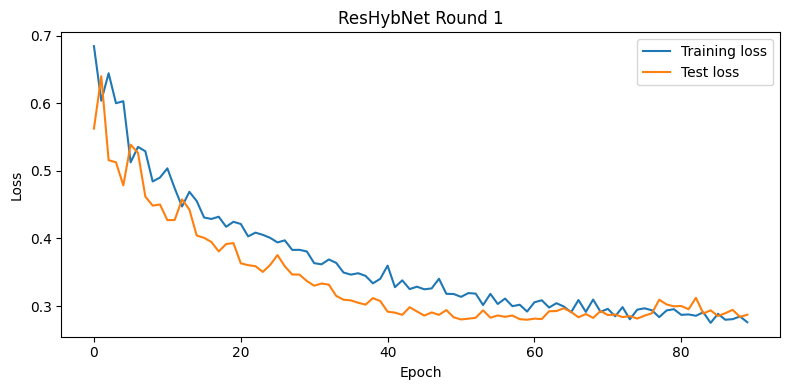


Training round: 2/10
Validation loss: inf --> 0.935488. Saving model...
Validation loss: 0.935488 --> 0.572802. Saving model...
EarlyStopping counter: 1 out of 30
EarlyStopping counter: 2 out of 30
EarlyStopping counter: 3 out of 30
Validation loss: 0.572802 --> 0.547271. Saving model...
EarlyStopping counter: 1 out of 30
EarlyStopping counter: 2 out of 30
EarlyStopping counter: 3 out of 30
Epoch 10 | Train Loss: 0.610587 | Test Loss: 0.544192 | Test Accuracy: 0.7430
Validation loss: 0.547271 --> 0.544192. Saving model...
EarlyStopping counter: 1 out of 30
EarlyStopping counter: 2 out of 30
EarlyStopping counter: 3 out of 30
EarlyStopping counter: 4 out of 30
Validation loss: 0.544192 --> 0.529232. Saving model...
Validation loss: 0.529232 --> 0.504648. Saving model...
Validation loss: 0.504648 --> 0.492347. Saving model...
Validation loss: 0.492347 --> 0.485119. Saving model...
Validation loss: 0.485119 --> 0.473877. Saving model...
Epoch 20 | Train Loss: 0.497236 | Test Loss: 0.4601

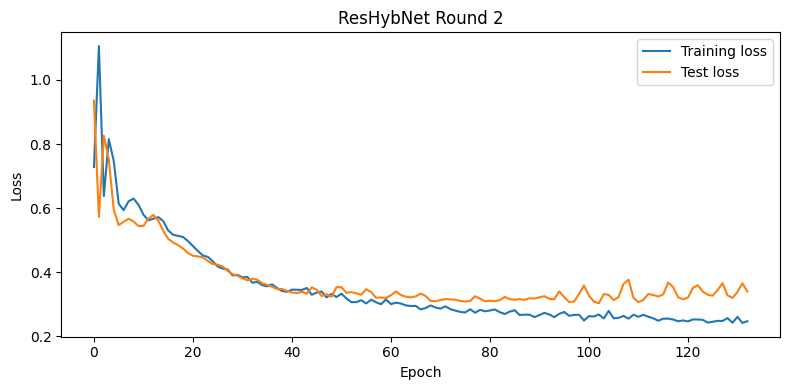


Training round: 3/10
Validation loss: inf --> 0.767307. Saving model...
Validation loss: 0.767307 --> 0.709486. Saving model...
Validation loss: 0.709486 --> 0.612138. Saving model...
Validation loss: 0.612138 --> 0.587738. Saving model...
EarlyStopping counter: 1 out of 30
EarlyStopping counter: 2 out of 30
Validation loss: 0.587738 --> 0.564993. Saving model...
Validation loss: 0.564993 --> 0.534482. Saving model...
Validation loss: 0.534482 --> 0.517151. Saving model...
Epoch 10 | Train Loss: 0.575983 | Test Loss: 0.511654 | Test Accuracy: 0.7552
Validation loss: 0.517151 --> 0.511654. Saving model...
Validation loss: 0.511654 --> 0.509946. Saving model...
Validation loss: 0.509946 --> 0.504414. Saving model...
Validation loss: 0.504414 --> 0.496290. Saving model...
Validation loss: 0.496290 --> 0.494835. Saving model...
Validation loss: 0.494835 --> 0.494279. Saving model...
Validation loss: 0.494279 --> 0.485106. Saving model...
Validation loss: 0.485106 --> 0.476084. Saving mode

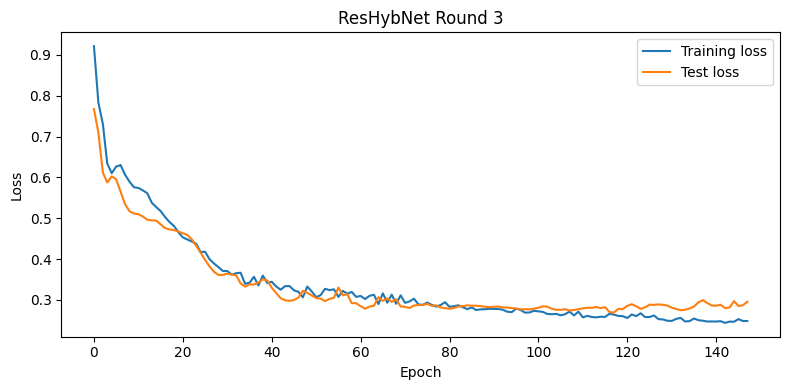


Training round: 4/10
Validation loss: inf --> 0.928569. Saving model...
Validation loss: 0.928569 --> 0.600828. Saving model...
EarlyStopping counter: 1 out of 30
EarlyStopping counter: 2 out of 30
EarlyStopping counter: 3 out of 30
Validation loss: 0.600828 --> 0.574852. Saving model...
Validation loss: 0.574852 --> 0.560687. Saving model...
Validation loss: 0.560687 --> 0.556767. Saving model...
Validation loss: 0.556767 --> 0.550448. Saving model...
Epoch 10 | Train Loss: 0.614114 | Test Loss: 0.539610 | Test Accuracy: 0.7483
Validation loss: 0.550448 --> 0.539610. Saving model...
Validation loss: 0.539610 --> 0.528635. Saving model...
Validation loss: 0.528635 --> 0.524312. Saving model...
EarlyStopping counter: 1 out of 30
EarlyStopping counter: 2 out of 30
Validation loss: 0.524312 --> 0.519702. Saving model...
Validation loss: 0.519702 --> 0.499233. Saving model...
Validation loss: 0.499233 --> 0.483579. Saving model...
Validation loss: 0.483579 --> 0.476188. Saving model...
Va

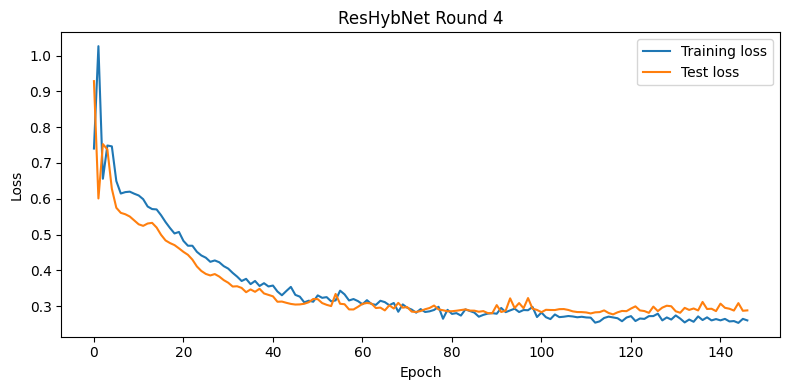


Training round: 5/10
Validation loss: inf --> 0.754901. Saving model...
Validation loss: 0.754901 --> 0.671647. Saving model...
Validation loss: 0.671647 --> 0.609934. Saving model...
EarlyStopping counter: 1 out of 30
EarlyStopping counter: 2 out of 30
EarlyStopping counter: 3 out of 30
EarlyStopping counter: 4 out of 30
Validation loss: 0.609934 --> 0.595354. Saving model...
Validation loss: 0.595354 --> 0.570800. Saving model...
Epoch 10 | Train Loss: 0.586227 | Test Loss: 0.551498 | Test Accuracy: 0.7675
Validation loss: 0.570800 --> 0.551498. Saving model...
Validation loss: 0.551498 --> 0.534607. Saving model...
Validation loss: 0.534607 --> 0.516309. Saving model...
Validation loss: 0.516309 --> 0.499213. Saving model...
Validation loss: 0.499213 --> 0.493333. Saving model...
Validation loss: 0.493333 --> 0.481446. Saving model...
Validation loss: 0.481446 --> 0.461120. Saving model...
Validation loss: 0.461120 --> 0.452509. Saving model...
Validation loss: 0.452509 --> 0.44689

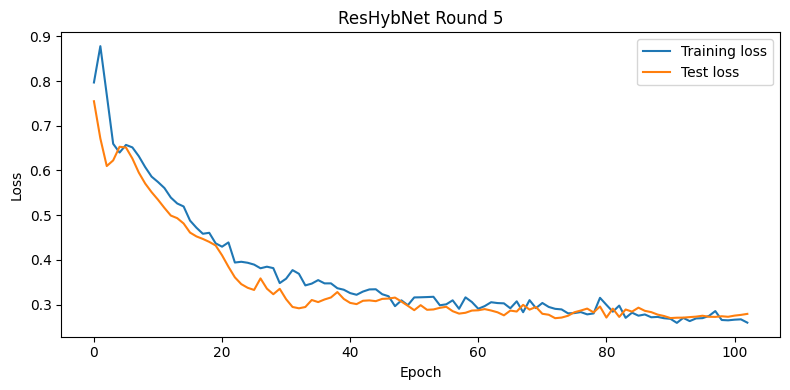


Training round: 6/10
Validation loss: inf --> 1.094911. Saving model...
Validation loss: 1.094911 --> 0.606342. Saving model...
EarlyStopping counter: 1 out of 30
EarlyStopping counter: 2 out of 30
EarlyStopping counter: 3 out of 30
Validation loss: 0.606342 --> 0.591121. Saving model...
Validation loss: 0.591121 --> 0.581129. Saving model...
EarlyStopping counter: 1 out of 30
EarlyStopping counter: 2 out of 30
Epoch 10 | Train Loss: 0.662859 | Test Loss: 0.589643 | Test Accuracy: 0.6643
EarlyStopping counter: 3 out of 30
Validation loss: 0.581129 --> 0.578759. Saving model...
Validation loss: 0.578759 --> 0.573317. Saving model...
EarlyStopping counter: 1 out of 30
EarlyStopping counter: 2 out of 30
EarlyStopping counter: 3 out of 30
Validation loss: 0.573317 --> 0.561026. Saving model...
Validation loss: 0.561026 --> 0.538551. Saving model...
Validation loss: 0.538551 --> 0.514038. Saving model...
Validation loss: 0.514038 --> 0.493494. Saving model...
Epoch 20 | Train Loss: 0.53730

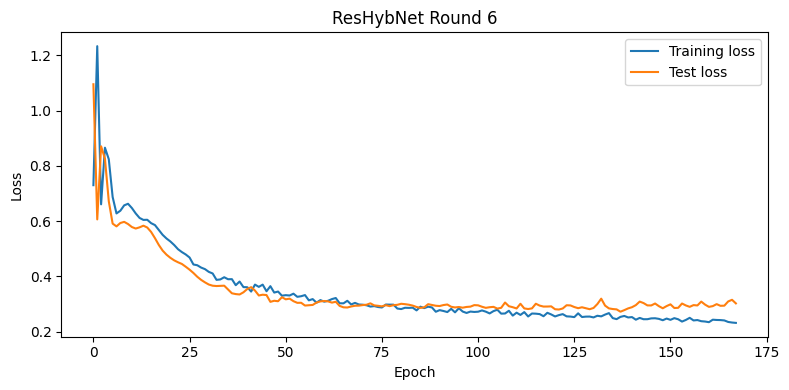


Training round: 7/10
Validation loss: inf --> 0.744285. Saving model...
Validation loss: 0.744285 --> 0.638491. Saving model...
Validation loss: 0.638491 --> 0.612715. Saving model...
EarlyStopping counter: 1 out of 30
Validation loss: 0.612715 --> 0.611244. Saving model...
Validation loss: 0.611244 --> 0.586494. Saving model...
Validation loss: 0.586494 --> 0.563082. Saving model...
Validation loss: 0.563082 --> 0.545181. Saving model...
Validation loss: 0.545181 --> 0.528864. Saving model...
Epoch 10 | Train Loss: 0.539548 | Test Loss: 0.508241 | Test Accuracy: 0.7850
Validation loss: 0.528864 --> 0.508241. Saving model...
Validation loss: 0.508241 --> 0.488202. Saving model...
Validation loss: 0.488202 --> 0.477979. Saving model...
Validation loss: 0.477979 --> 0.469606. Saving model...
Validation loss: 0.469606 --> 0.460467. Saving model...
Validation loss: 0.460467 --> 0.458030. Saving model...
Validation loss: 0.458030 --> 0.444191. Saving model...
Validation loss: 0.444191 --> 

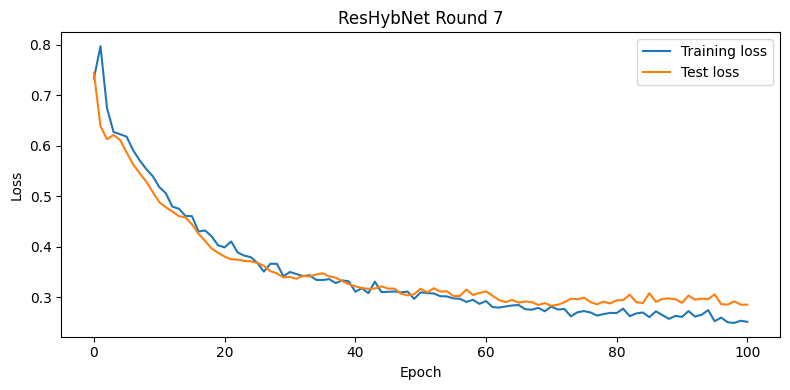


Training round: 8/10
Validation loss: inf --> 1.462690. Saving model...
Validation loss: 1.462690 --> 0.729326. Saving model...
Validation loss: 0.729326 --> 0.602978. Saving model...
EarlyStopping counter: 1 out of 30
EarlyStopping counter: 2 out of 30
Validation loss: 0.602978 --> 0.580075. Saving model...
Validation loss: 0.580075 --> 0.569350. Saving model...
EarlyStopping counter: 1 out of 30
EarlyStopping counter: 2 out of 30
Epoch 10 | Train Loss: 0.621582 | Test Loss: 0.647787 | Test Accuracy: 0.5507
EarlyStopping counter: 3 out of 30
EarlyStopping counter: 4 out of 30
EarlyStopping counter: 5 out of 30
Validation loss: 0.569350 --> 0.564887. Saving model...
Validation loss: 0.564887 --> 0.538183. Saving model...
Validation loss: 0.538183 --> 0.525027. Saving model...
Validation loss: 0.525027 --> 0.516024. Saving model...
Validation loss: 0.516024 --> 0.504473. Saving model...
Validation loss: 0.504473 --> 0.491863. Saving model...
Validation loss: 0.491863 --> 0.482688. Savi

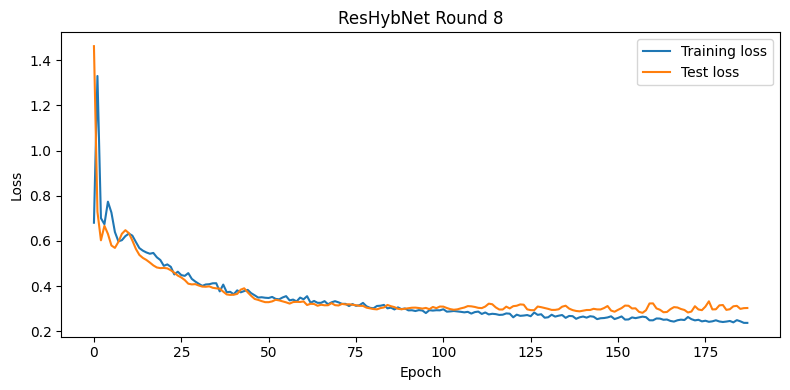


Training round: 9/10
Validation loss: inf --> 0.684186. Saving model...
Validation loss: 0.684186 --> 0.584140. Saving model...
EarlyStopping counter: 1 out of 30
EarlyStopping counter: 2 out of 30
Validation loss: 0.584140 --> 0.557412. Saving model...
Validation loss: 0.557412 --> 0.541316. Saving model...
EarlyStopping counter: 1 out of 30
Validation loss: 0.541316 --> 0.532224. Saving model...
Validation loss: 0.532224 --> 0.508257. Saving model...
Epoch 10 | Train Loss: 0.533739 | Test Loss: 0.506402 | Test Accuracy: 0.8252
Validation loss: 0.508257 --> 0.506402. Saving model...
EarlyStopping counter: 1 out of 30
Validation loss: 0.506402 --> 0.504759. Saving model...
Validation loss: 0.504759 --> 0.475859. Saving model...
Validation loss: 0.475859 --> 0.465503. Saving model...
EarlyStopping counter: 1 out of 30
EarlyStopping counter: 2 out of 30
Validation loss: 0.465503 --> 0.463750. Saving model...
EarlyStopping counter: 1 out of 30
EarlyStopping counter: 2 out of 30
Epoch 20 

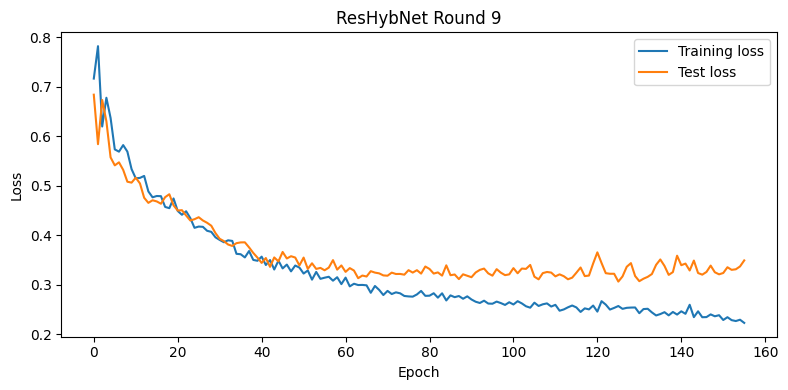


Training round: 10/10
Validation loss: inf --> 0.581557. Saving model...
EarlyStopping counter: 1 out of 30
Validation loss: 0.581557 --> 0.539970. Saving model...
EarlyStopping counter: 1 out of 30
EarlyStopping counter: 2 out of 30
Validation loss: 0.539970 --> 0.531531. Saving model...
EarlyStopping counter: 1 out of 30
EarlyStopping counter: 2 out of 30
Validation loss: 0.531531 --> 0.524469. Saving model...
Epoch 10 | Train Loss: 0.549725 | Test Loss: 0.495281 | Test Accuracy: 0.7902
Validation loss: 0.524469 --> 0.495281. Saving model...
EarlyStopping counter: 1 out of 30
Validation loss: 0.495281 --> 0.493577. Saving model...
Validation loss: 0.493577 --> 0.474693. Saving model...
Validation loss: 0.474693 --> 0.464315. Saving model...
EarlyStopping counter: 1 out of 30
EarlyStopping counter: 2 out of 30
EarlyStopping counter: 3 out of 30
EarlyStopping counter: 4 out of 30
EarlyStopping counter: 5 out of 30
Epoch 20 | Train Loss: 0.459253 | Test Loss: 0.441827 | Test Accuracy: 

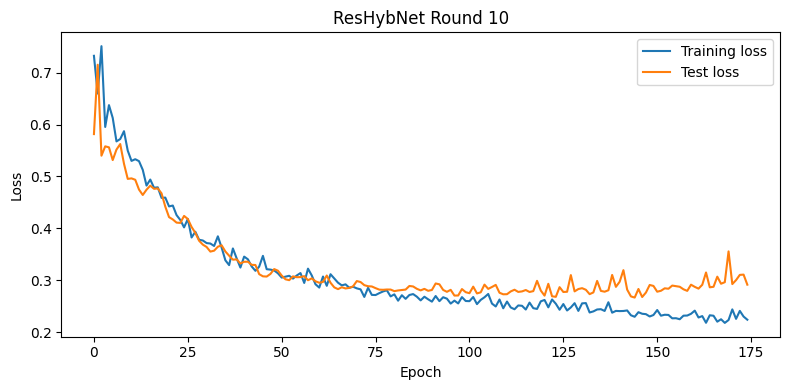


Training completed.


In [7]:
LR = 0.01
WEIGHT_DECAY = 5e-4
TRAIN_ROUNDS = 10
EPOCHS = 1000
PATIENCE = 30
DELTA = 0.0001

CNN = 'CNN'
GNN = 'GCN'
RESIDUAL = 'YES'

results = []

print("Model: ResHybNet")
print("CNN:", CNN)
print("GNN:", GNN)
print("Residual:", RESIDUAL)
print("Learning rate:", LR)
print("Training rounds:", TRAIN_ROUNDS)

for r in trange(TRAIN_ROUNDS):

    print(f"\nTraining round: {r + 1}/{TRAIN_ROUNDS}")

    model = ResHybNet(
        input_dim=data.num_node_features,
        output_dim=data.num_node_features,
        cnn=CNN,
        gnn=GNN,
        residual=RESIDUAL
    ).to(device)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=LR,
        weight_decay=WEIGHT_DECAY
    )

    best_model_path = os.path.join(
        MODEL_DIR,
        f"{CNN}_{GNN}_manual+lstm_seq74_{RESIDUAL}_{r}round_best.pt"
    )

    early_stopping = EarlyStopping(
        save_path=best_model_path,
        verbose=True,
        patience=PATIENCE,
        delta=DELTA,
        metric='loss'
    )

    train_loss_s = []
    test_loss_s = []

    for epoch in range(EPOCHS):

        model.train()
        optimizer.zero_grad()

        out = model(data)

        train_log_prob = torch.log(
            out[data.train_mask].clamp_min(1e-12)
        )

        loss = F.nll_loss(
            train_log_prob,
            data.y[data.train_mask]
        )

        loss.backward()
        optimizer.step()

        train_loss_s.append(loss.item())

        model.eval()

        with torch.no_grad():
            out = model(data)

            test_log_prob = torch.log(
                out[data.test_mask].clamp_min(1e-12)
            )

            test_loss = F.nll_loss(
                test_log_prob,
                data.y[data.test_mask]
            )

            test_loss_value = test_loss.item()

            pred = out[data.test_mask].argmax(dim=1)
            true = data.y[data.test_mask]

            test_acc = accuracy_score(
                true.cpu().numpy(),
                pred.cpu().numpy()
            )

        test_loss_s.append(test_loss_value)

        if (epoch + 1) % 10 == 0:
            print(
                f"Epoch {epoch + 1} | "
                f"Train Loss: {loss.item():.6f} | "
                f"Test Loss: {test_loss_value:.6f} | "
                f"Test Accuracy: {test_acc:.4f}"
            )

        early_stopping(test_loss_value, model)

        if early_stopping.early_stop:
            print("Early stopping at epoch:", epoch + 1)
            break

    model.load_state_dict(
        torch.load(
            best_model_path,
            map_location=device,
            weights_only=True
        )
    )

    model.eval()

    with torch.no_grad():
        out = model(data)
        pred = out[data.test_mask].argmax(dim=1)
        true = data.y[data.test_mask]

        y_pred = pred.cpu().numpy()
        y_true = true.cpu().numpy()

    test_acc = accuracy_score(y_true, y_pred)
    test_pre = precision_score(y_true, y_pred, zero_division=0)
    test_rec = recall_score(y_true, y_pred, zero_division=0)
    test_f1 = f1_score(y_true, y_pred, zero_division=0)

    results.append({
        "model": f"{CNN}_{GNN}",
        "features": "manual+lstm_seq74",
        "round": r,
        "test_acc": test_acc,
        "test_pre": test_pre,
        "test_rec": test_rec,
        "test_f1": test_f1,
        "epoch": len(train_loss_s),
        "best_test_loss": min(test_loss_s)
    })

    print(
        f"\nRound {r + 1} results:"
        f"\nAccuracy: {test_acc:.4f}"
        f"\nPrecision: {test_pre:.4f}"
        f"\nRecall: {test_rec:.4f}"
        f"\nF1-score: {test_f1:.4f}"
    )

    plt.figure(figsize=(8, 4))
    plt.plot(train_loss_s, label="Training loss")
    plt.plot(test_loss_s, label="Test loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title(f"ResHybNet Round {r + 1}")
    plt.legend()
    plt.tight_layout()
    plt.show()

    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

print("\nTraining completed.")

In [8]:
results_df = pd.DataFrame(results)

RESULT_PATH = os.path.join(
    RESULT_DIR,
    "CNN_GCN_manual+lstm_seq74_YES_result.csv"
)

results_df.to_csv(RESULT_PATH, index=False)

display(results_df)

print("\nAverage performance across 10 rounds:")

for metric in ["test_acc", "test_pre", "test_rec", "test_f1"]:
    print(f"{metric}: {results_df[metric].mean():.4f}")

print("\nResults saved to:", RESULT_PATH)

,model,features,round,test_acc,test_pre,test_rec,test_f1,epoch,best_test_loss
0,CNN_GCN,manual+lstm_seq74,0,0.914336,0.904059,0.914179,0.909091,90,0.279658
1,CNN_GCN,manual+lstm_seq74,1,0.912587,0.916031,0.895522,0.905660,133,0.303281
2,CNN_GCN,manual+lstm_seq74,2,0.928322,0.921933,0.925373,0.923650,148,0.269483
3,CNN_GCN,manual+lstm_seq74,3,0.923077,0.921053,0.914179,0.917603,147,0.276987
4,CNN_GCN,manual+lstm_seq74,4,0.921329,0.905455,0.929104,0.917127,103,0.269584
5,CNN_GCN,manual+lstm_seq74,5,0.923077,0.911765,0.925373,0.918519,168,0.272653
6,CNN_GCN,manual+lstm_seq74,6,0.916084,0.904412,0.917910,0.911111,101,0.282929
7,CNN_GCN,manual+lstm_seq74,7,0.924825,0.915129,0.925373,0.920223,188,0.281827
8,CNN_GCN,manual+lstm_seq74,8,0.914336,0.895307,0.925373,0.910092,156,0.306374
9,CNN_GCN,manual+lstm_seq74,9,0.917832,0.913858,0.910448,0.912150,175,0.266710



Average performance across 10 rounds:
test_acc: 0.9196
test_pre: 0.9109
test_rec: 0.9183
test_f1: 0.9145

Results saved to: /content/drive/MyDrive/Insider_Threat_Project/ResHybnet_results/CNN_GCN_manual+lstm_seq74_YES_result.csv


In [9]:
final_checkpoint = results[-1]["round"]

best_model_path = os.path.join(
    MODEL_DIR,
    f"{CNN}_{GNN}_manual+lstm_seq74_{RESIDUAL}_{final_checkpoint}round_best.pt"
)

final_model = ResHybNet(
    input_dim=data.num_node_features,
    output_dim=data.num_node_features,
    cnn=CNN,
    gnn=GNN,
    residual=RESIDUAL
).to(device)

final_model.load_state_dict(
    torch.load(
        best_model_path,
        map_location=device,
        weights_only=True
    )
)

final_model.eval()

with torch.no_grad():
    out = final_model(data)
    y_pred = out[data.test_mask].argmax(dim=1).cpu().numpy()
    y_true = data.y[data.test_mask].cpu().numpy()

print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=["Class 0", "Class 1"],
    zero_division=0
))

print("Confusion matrix:")
print(confusion_matrix(y_true, y_pred, labels=[0, 1]))

              precision    recall  f1-score   support

     Class 0       0.92      0.92      0.92       304
     Class 1       0.91      0.91      0.91       268

    accuracy                           0.92       572
   macro avg       0.92      0.92      0.92       572
weighted avg       0.92      0.92      0.92       572

Confusion matrix:
[[281  23]
 [ 24 244]]
